# 02 - Healthy baseline: what does normal look like?

The healthy reference is what every later step is measured against, so this notebook answers four
questions:

1. What is the healthy operating point, and where does the pressure go along the line?
2. How repeatable is it: how much do healthy recordings differ from each other?
3. What is the "noise" made of? (Answer: mostly the pump itself.)
4. What healthy limits should a monitor use, and what are their limits?

Data: six healthy recordings, 60 s each at 1 kHz, pump at 400 rpm, all valves in their healthy
positions, recorded one minute apart between 09:58 and 10:04.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fueltwin import baseline, config, features, plotting as pl, pump, rig

pl.use_style()
pd.set_option("display.precision", 4)
data, cat = rig.load_all()
w = features.load_windows(1.0)
hc_w = w[w["condition"] == "HC"]
hc = data[data["condition"] == "HC"]
HC_RUNS = [f"HC-{i}" for i in range(1, 7)]

## 1. The healthy operating point

Run averages of every recording (P3-P5 converted to absolute pressure with the standard atmosphere).

In [2]:
cols = ["P1", "P2", "P3", "P4", "P5", "Q", "rpm", "dP_filter", "dP_pump", "dP_valve", "dP_nozzle", "fpr"]
run_means = hc_w.groupby("run_id")[cols].mean().loc[HC_RUNS]
op = run_means.agg(["mean", "std", "min", "max"]).T
op.columns = ["mean", "sd between runs", "min run", "max run"]
op.to_csv(config.TABLE_DIR / "02_healthy_operating_point.csv")
op

,mean,sd between runs,min run,max run
P1,0.9101,0.0011,0.9086,0.9113
P2,0.8668,0.0013,0.8657,0.8693
P3,1.3332,0.0005,1.3327,1.3338
P4,1.2334,0.0004,1.2327,1.2337
P5,1.1296,0.0002,1.1292,1.1298
Q,0.7157,0.0004,0.7149,0.7160
rpm,399.9812,0.0460,399.9248,400.0315
dP_filter,0.0433,0.0009,0.0418,0.0443
dP_pump,0.4664,0.0014,0.4635,0.4671
dP_valve,0.0999,0.0002,0.0996,0.1001


**Reading the table**

* The pump lifts the fluid by **0.467 bar** (P3 - P2) and delivers **0.716 L/min** at 400 rpm, which is
  **1.79 mL per revolution** reaching the flow meter.
* The suction side runs below atmospheric pressure (P2 = 0.867 bar abs), as expected for a pump
  drawing through a filter from a low tank.
* Downstream, the pressure is spent almost evenly: about 0.10 bar across the shut-off valve path,
  0.10 bar across the nozzle path and 0.12 bar (P5 gauge) in the final pipe and flow meter to the sump.

The pressure profile along the line (hydraulic grade line) makes the budget visible:

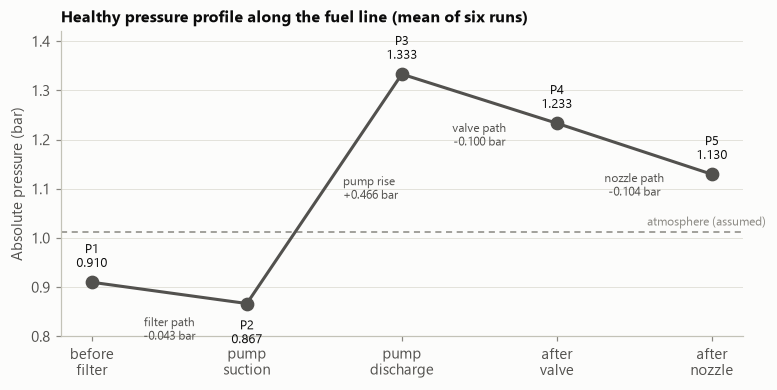

In [3]:
prof = run_means[["P1", "P2", "P3", "P4", "P5"]].mean()
x = np.arange(5)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axhline(config.P_ATM_BAR, color=pl.MUTED, lw=1, ls=(0, (4, 3)))
ax.text(4.35, config.P_ATM_BAR + 0.006, "atmosphere (assumed)", fontsize=8, color=pl.MUTED, ha="right", va="bottom")
ax.plot(x, prof.values, color=pl.CONDITION_COLORS["HC"], marker="o", ms=8)
for i, (k, v) in enumerate(prof.items()):
    ax.annotate(f"{k}\n{v:.3f}", (i, v), xytext=(0, 10 if i != 1 else -26), textcoords="offset points",
                ha="center", fontsize=8.5, color=pl.INK)
segments = [("filter path", 0, 1, op.loc["dP_filter", "mean"], -1), ("pump rise", 1, 2, op.loc["dP_pump", "mean"], 1),
            ("valve path", 2, 3, op.loc["dP_valve", "mean"], -1), ("nozzle path", 3, 4, op.loc["dP_nozzle", "mean"], -1)]
for name, a, b, dp, sign in segments:
    xm, ym = (a + b) / 2, (prof.iloc[a] + prof.iloc[b]) / 2
    xy = (xm + 0.12, ym) if sign > 0 else (xm, ym - 0.075)
    ax.text(*xy, f"{name}\n{'+' if sign > 0 else '-'}{dp:.3f} bar", ha="left" if sign > 0 else "center",
            va="center", fontsize=8, color=pl.INK_2)
ax.set_xticks(x, ["before\nfilter", "pump\nsuction", "pump\ndischarge", "after\nvalve", "after\nnozzle"])
ax.set_ylabel("Absolute pressure (bar)")
ax.set_ylim(0.8, 1.42)
ax.set_title("Healthy pressure profile along the fuel line (mean of six runs)")
ax.grid(axis="x", visible=False)
pl.save(fig, "02_pressure_profile")
plt.show()

## 2. What the raw signals look like

Two seconds of 1 kHz data from one healthy run, and the 1 s window means of all six runs. The raw
traces are dominated by a regular ripple; the window means are flat to within a few mbar.

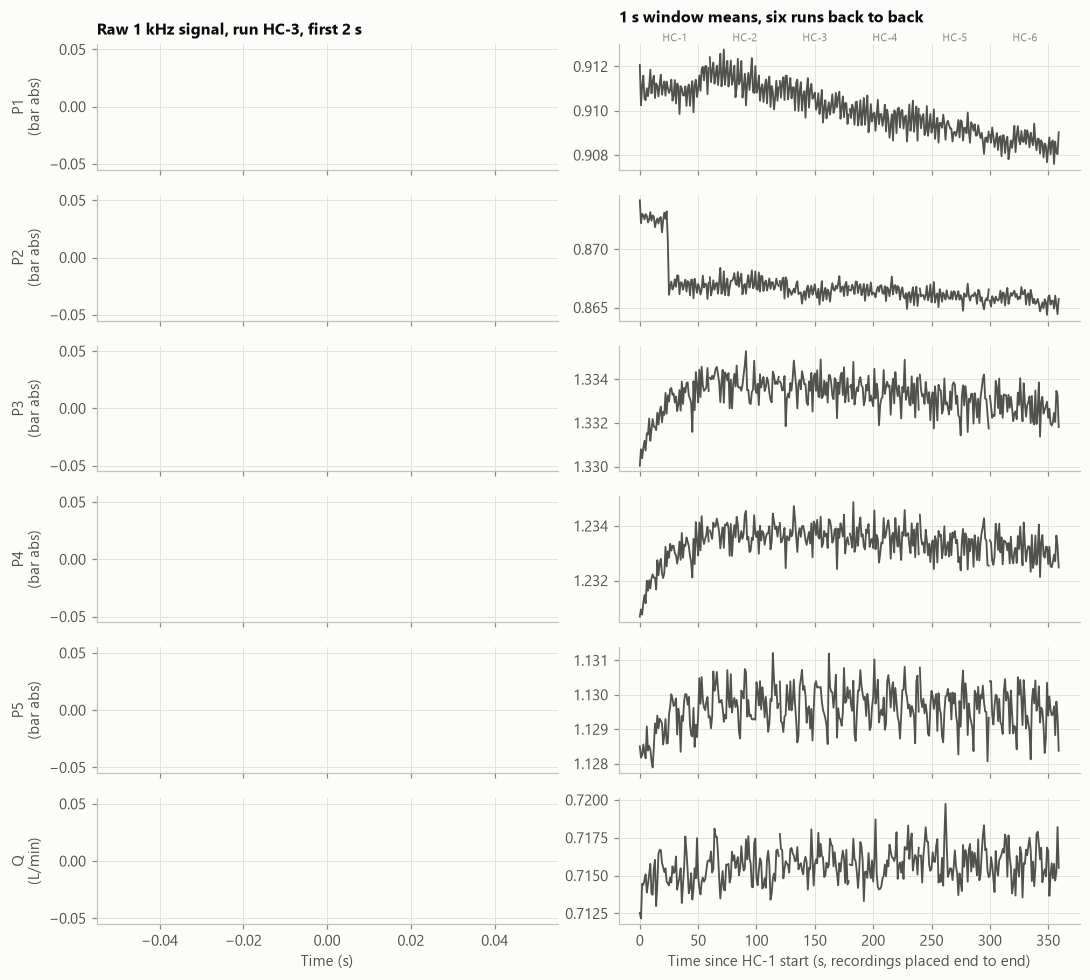

In [4]:
show = ["P1", "P2", "P3", "P4", "P5", "Q"]
units = {c: "bar abs" for c in show[:-1]} | {"Q": "L/min"}
seg = hc[(hc["run_id"] == "HC-3") & (hc["t"] < 2.0)]
fig, axes = plt.subplots(len(show), 2, figsize=(10, 9), sharex="col")
for i, c in enumerate(show):
    a = axes[i, 0]
    a.plot(seg["t"], seg[c], lw=0.8, color=pl.CONDITION_COLORS["HC"])
    a.set_ylabel(f"{c}\n({units[c]})")
    b = axes[i, 1]
    for j, r in enumerate(HC_RUNS):
        g = hc_w[hc_w["run_id"] == r]
        b.plot(g["t_start_s"] + 60 * j, g[c], lw=1.2, color=pl.CONDITION_COLORS["HC"])
        if i == 0:
            b.text(60 * j + 30, 1.0, r, transform=b.get_xaxis_transform(), ha="center", va="bottom",
                   fontsize=7.5, color=pl.MUTED)
axes[0, 0].set_title("Raw 1 kHz signal, run HC-3, first 2 s")
axes[0, 1].set_title("1 s window means, six runs back to back", pad=14)
axes[-1, 0].set_xlabel("Time (s)")
axes[-1, 1].set_xlabel("Time since HC-1 start (s, recordings placed end to end)")
fig.tight_layout()
pl.save(fig, "02_healthy_signals")
plt.show()

Two things stand out on the right-hand panels:

* **P1 and P2 fall steadily** from run to run (about 2.5 mbar over five minutes). P1 is an absolute
  pressure that includes the head of water in the main tank, and the rig pumps water from the main
  tank to the sump tank, so a falling tank level is the most likely cause. It is a real, slow,
  non-fault change in the healthy system.
* The downstream pressures and the flow are flat to within about 1 mbar and 0.001 L/min.

## 3. Repeatability: within a run versus between runs

Three levels of variation, per variable:
* **raw 1 kHz sd**: sensor noise plus pump ripple (what the old analysis used for its healthy band);
* **within-run sd of 1 s means**: what is left after averaging the ripple out;
* **between-run sd**: how much the six recordings disagree with each other.

In [5]:
raw_sd = hc.groupby("run_id", observed=True)[cols].std().mean()
vt = baseline.variance_table(w, cols, raw_sd)
vt.to_csv(config.TABLE_DIR / "02_variance_table.csv")
vt

,mean,sd_raw_1kHz,sd_between_runs,sd_within_run_1s,range_between_runs,cv_between_pct
P1,0.9101,0.0129,0.0011,0.0005,0.0027,0.1193
P2,0.8668,0.0145,0.0013,0.0013,0.0035,0.1477
P3,1.3332,0.0044,0.0005,0.0007,0.0011,0.0346
P4,1.2334,0.0028,0.0004,0.0005,0.0010,0.0316
P5,1.1296,0.0070,0.0002,0.0006,0.0006,0.0209
Q,0.7157,0.0028,0.0004,0.0011,0.0011,0.0553
rpm,399.9812,0.5995,0.0460,0.4425,0.1067,0.0115
dP_filter,0.0433,0.0080,0.0009,0.0012,0.0025,2.0538
dP_pump,0.4664,0.0167,0.0014,0.0018,0.0037,0.3101
dP_valve,0.0999,0.0041,0.0002,0.0003,0.0004,0.1725


Averaging over 1 s removes most of the raw scatter (for P3 the sd falls from 4.4 mbar to well under
1 mbar), and the six recordings agree with each other to within a fraction of a percent: the flow
varies by 0.06 % between runs. The healthy system is very repeatable **over five minutes**. Whether it
is repeatable **over a day** cannot be tested here, because no healthy recording was taken after
10:04 (notebook 03 shows it is not).

Distribution view of the same point: the kernel density of the raw samples overlaps almost perfectly
between runs (left), while the 1 s window means separate the slow P1 drift (right).

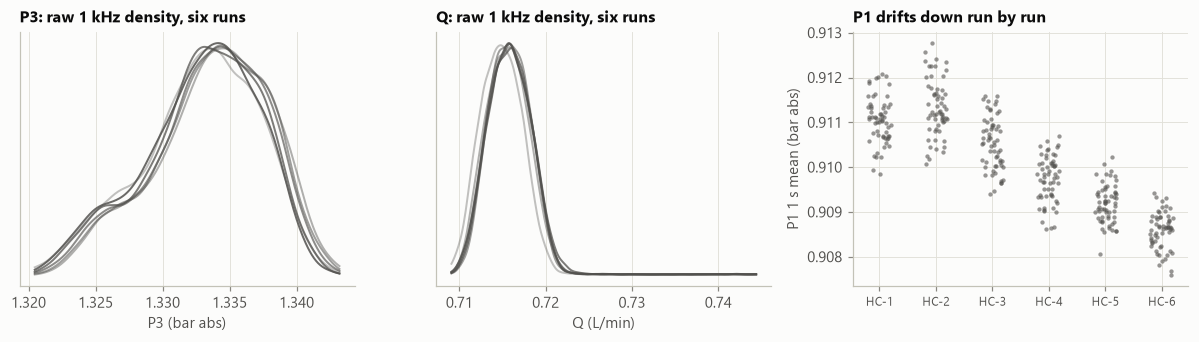

In [6]:
from scipy.stats import gaussian_kde

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, c in zip(axes[:2], ["P3", "Q"]):
    grid = np.linspace(hc[c].quantile(0.001), hc[c].quantile(0.999), 300)
    for j, r in enumerate(HC_RUNS):
        xs = hc.loc[hc["run_id"] == r, c].to_numpy("float64")[::5]
        ax.plot(grid, gaussian_kde(xs)(grid), lw=1.3, color=pl.CONDITION_COLORS["HC"], alpha=0.35 + 0.1 * j)
    ax.set_xlabel(f"{c} ({units[c]})")
    ax.set_yticks([])
    ax.set_title(f"{c}: raw 1 kHz density, six runs")
ax = axes[2]
for j, r in enumerate(HC_RUNS):
    g = hc_w[hc_w["run_id"] == r]
    ax.scatter(np.full(len(g), j) + np.random.default_rng(j).uniform(-0.2, 0.2, len(g)), g["P1"], s=8,
               color=pl.CONDITION_COLORS["HC"], alpha=0.6, linewidths=0)
ax.set_xticks(range(6), HC_RUNS, rotation=0, fontsize=8)
ax.set_ylabel("P1 1 s mean (bar abs)")
ax.set_title("P1 drifts down run by run")
fig.tight_layout()
pl.save(fig, "02_healthy_distributions")
plt.show()

## 4. What is the "noise"? The pump's own signature

Power spectra of the healthy signals (Welch, 16 s segments, averaged over the six runs). The pump
turns at 400 rpm = **6.67 Hz**.

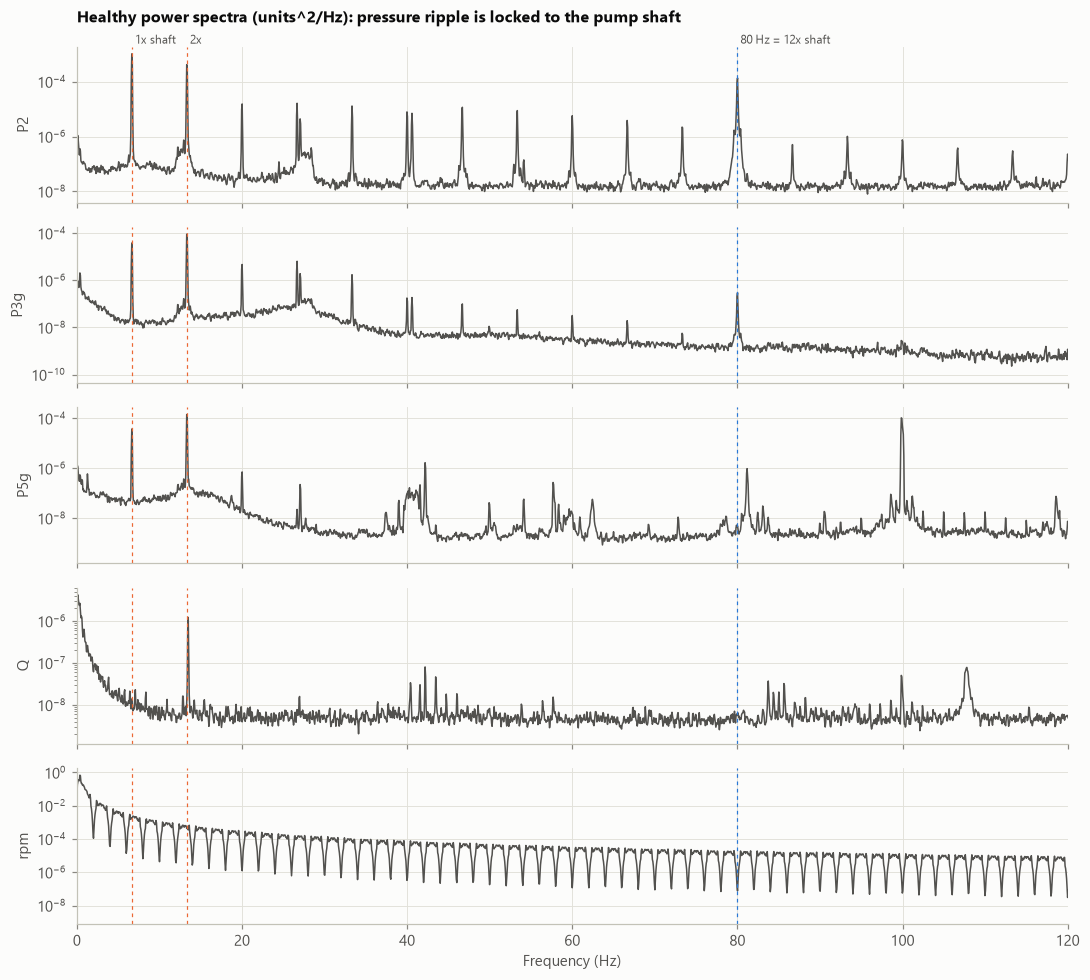

In [7]:
spec_cols = ["P2", "P3g", "P5g", "Q", "rpm"]
spec = {}
for c in spec_cols:
    ps = []
    for r in HC_RUNS:
        f, p = features.psd(hc.loc[hc["run_id"] == r, c].to_numpy("float64"), nperseg=16384)
        ps.append(p)
    spec[c] = (f, np.mean(ps, axis=0))

shaft = 400 / 60
fig, axes = plt.subplots(len(spec_cols), 1, figsize=(10, 9), sharex=True)
for ax, c in zip(axes, spec_cols):
    f, p = spec[c]
    ax.semilogy(f, p, lw=1, color=pl.CONDITION_COLORS["HC"])
    ax.set_ylabel(c)
    for k in (1, 2):
        ax.axvline(k * shaft, color=pl.SERIES[1], lw=0.8, ls=(0, (3, 3)))
    ax.axvline(12 * shaft, color=pl.SERIES[0], lw=0.8, ls=(0, (3, 3)))
axes[0].text(shaft, 1.02, " 1x shaft", transform=axes[0].get_xaxis_transform(), fontsize=8, color=pl.INK_2)
axes[0].text(2 * shaft, 1.02, " 2x", transform=axes[0].get_xaxis_transform(), fontsize=8, color=pl.INK_2)
axes[0].text(12 * shaft, 1.02, " 80 Hz = 12x shaft", transform=axes[0].get_xaxis_transform(), fontsize=8, color=pl.INK_2)
axes[0].set_title("Healthy power spectra (units^2/Hz): pressure ripple is locked to the pump shaft", pad=16)
axes[-1].set_xlabel("Frequency (Hz)")
axes[-1].set_xlim(0, 120)
fig.tight_layout()
pl.save(fig, "02_healthy_spectra")
plt.show()

In [8]:
bands = {}
for c in spec_cols:
    f, p = spec[c]
    total = np.trapezoid(p, f)
    near = lambda h: np.trapezoid(p[(f > h * shaft - 0.4) & (f < h * shaft + 0.4)], f[(f > h * shaft - 0.4) & (f < h * shaft + 0.4)])
    bands[c] = {"share at 1x shaft (%)": 100 * near(1) / total, "share at 2x shaft (%)": 100 * near(2) / total,
                "share below 2 Hz (%)": 100 * np.trapezoid(p[f < 2], f[f < 2]) / total,
                "share above 60 Hz (%)": 100 * np.trapezoid(p[f > 60], f[f > 60]) / total}
pd.DataFrame(bands).T.round(1)

,share at 1x shaft (%),share at 2x shaft (%),share below 2 Hz (%),share above 60 Hz (%)
P2,48.5,24.0,0.2,21.6
P3g,20.2,58.6,4.0,1.3
P5g,7.7,35.5,1.2,51.7
Q,0.1,1.7,23.2,69.1
rpm,0.4,0.1,90.7,0.3


* In the pressure signals around the pump (P2, P3) about three quarters of the fluctuation sits at
  **exactly the shaft frequency and its second harmonic** (43 % for P5, where electrical noise above
  60 Hz takes the rest). This is flow ripple from the gear pump plus any once-per-revolution unbalance or
  misalignment. The "noise" in the healthy data is
  largely deterministic pump behaviour.
* A peak at **80 Hz = 12 x shaft speed** appears on the pressure signals, consistent with the gear-mesh
  frequency of a 12-tooth gear (the tooth count is not documented, so this is an inference).
* The speed signal hunts slowly at about **0.37 Hz** (speed controller), and the same line appears
  faintly on P3 and P4.
* The flow meter's variance is mostly above 60 Hz (turbine and electrical noise) and below 2 Hz
  (slow wander), not at the pump orders.

This matters for the twin in two ways: pump-order amplitudes are a ready-made condition indicator for
the pump and coupling (gear wear changes mesh harmonics), and they can only be seen because the
2014 rig sampled at 1 kHz. The later PLC testbed logs every 200 ms (2.5 Hz Nyquist), which cannot
see any of these lines.

## 5. Healthy limits for monitoring

Limits are set on **1 s window means** as mean +/- 4 sd, where the sd combines within-run and
between-run variation. Using raw 1 kHz samples instead would make the band 2-14 times wider (see the last two
columns) and blind the monitor to small faults (and is the main weakness of a mean +/- 2 sd band on raw samples).

In [9]:
mon_cols = ["P1", "P2", "P3", "P4", "P5", "Q", "dP_filter", "dP_pump", "dP_valve", "dP_nozzle", "fpr"]
base = baseline.HealthyBaseline.fit(w, mon_cols)
env = base.envelope(k=4.0)
env["band (+/-) as % of mean"] = 100 * 4 * env["sd_total"] / env["mean"].abs()
env["raw-sample band (+/- 4 sd), % of mean"] = 100 * 4 * raw_sd.reindex(mon_cols) / env["mean"].abs()
env.to_csv(config.TABLE_DIR / "02_healthy_envelope.csv")
env

,mean,sd_within,sd_between,sd_total,lower,upper,band (+/-) as % of mean,"raw-sample band (+/- 4 sd), % of mean"
P1,0.9101,0.0005,0.0011,0.0012,0.9053,0.9149,0.5293,5.6908
P2,0.8668,0.0013,0.0013,0.0018,0.8595,0.8741,0.8392,6.6967
P3,1.3332,0.0007,0.0005,0.0008,1.3298,1.3366,0.2538,1.3059
P4,1.2334,0.0005,0.0004,0.0007,1.2307,1.2360,0.2165,0.8924
P5,1.1296,0.0006,0.0002,0.0006,1.1271,1.1321,0.2193,2.4686
Q,0.7157,0.0011,0.0004,0.0012,0.7111,0.7203,0.6446,1.5615
dP_filter,0.0433,0.0012,0.0009,0.0015,0.0372,0.0493,14.0709,73.8540
dP_pump,0.4664,0.0018,0.0014,0.0023,0.4573,0.4755,1.9579,14.3549
dP_valve,0.0999,0.0003,0.0002,0.0003,0.0987,0.1011,1.2188,16.5948
dP_nozzle,0.1038,0.0005,0.0002,0.0005,0.1017,0.1058,1.9450,25.0027


**Caveat that shapes the rest of the project.** These limits come from six recordings made within five
minutes, so they describe short-term repeatability only. The P1 drift already visible in that window
shows the system is not perfectly stationary; notebook 03 shows that by the afternoon the healthy
operating point has moved by more than these limits, without any fault. A monitor built on this
envelope alone would raise false alarms through the day, which is why the twin in notebook 06 uses
physics-based residuals with limits calibrated across the whole day instead.

## 6. The healthy point on the pump map

The healthy operating point is where the pump curve meets the system curve. For context, the
400 rpm pump test from the 2021 campaign (notebook 05) passes through almost the same point:

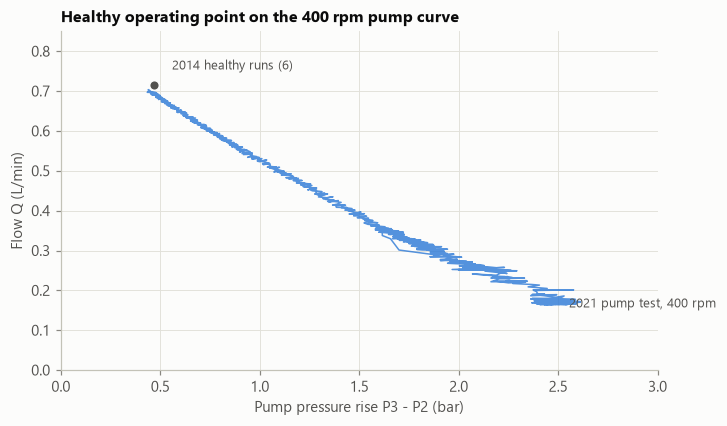

2021 pump line at the 2014 pressure rise: 0.691 L/min; measured in 2014: 0.716 L/min (+3.5 %)


In [10]:
pt = pump.load_campaign("initial")
p400 = pt[pt["nominal_rpm"] == 400]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(p400["dP_pump"], p400["Q"], lw=1, color=pl.SERIES[0], alpha=0.8)
pl.label_end(ax, p400["dP_pump"].iloc[-1], p400["Q"].iloc[-1], "2021 pump test, 400 rpm")
ax.scatter(run_means["dP_pump"], run_means["Q"], s=40, color=pl.CONDITION_COLORS["HC"], zorder=3,
           edgecolor=pl.SURFACE, linewidth=1)
ax.annotate("2014 healthy runs (6)", (run_means["dP_pump"].mean(), run_means["Q"].mean()),
            xytext=(12, 10), textcoords="offset points", fontsize=8.5, color=pl.INK_2)
ax.set_xlabel("Pump pressure rise P3 - P2 (bar)")
ax.set_ylabel("Flow Q (L/min)")
ax.set_xlim(0, 3)
ax.set_ylim(0, 0.85)
ax.set_title("Healthy operating point on the 400 rpm pump curve")
pl.save(fig, "02_operating_point_on_pump_curve")
plt.show()

line = np.polyfit(p400.loc[p400["dP_pump"] < 1.5, "dP_pump"], p400.loc[p400["dP_pump"] < 1.5, "Q"], 1)
expected = np.polyval(line, run_means["dP_pump"].mean())
print(f"2021 pump line at the 2014 pressure rise: {expected:.3f} L/min; measured in 2014: {run_means['Q'].mean():.3f} L/min "
      f"({100 * (run_means['Q'].mean() / expected - 1):+.1f} %)")

Seven years and a full rebuild of the control system apart, the healthy operating point sits within a
few percent of the 2021 pump line. Notebook 03 shows the 2014 pump curve is nevertheless steeper (more
internal leakage) than in 2021, so agreement at one point does not mean the same pump characteristic.

## Summary

| Quantity | Healthy value (mean of 6 runs) | Between-run sd |
|---|---|---|
| Pump speed | 400.0 rpm | 0.05 rpm |
| Flow at the end of the line | 0.716 L/min | 0.0004 |
| Pump pressure rise P3 - P2 | 0.467 bar | 0.0015 |
| Delivered flow per revolution | 1.79 mL/rev | 0.001 |
| Pressure drops: filter / valve / nozzle path | 0.043 / 0.100 / 0.104 bar | < 0.001 |

* The healthy system is highly repeatable over minutes; the remaining slow change (P1 falling with
  tank level) is physical, not a fault.
* Most of the high-frequency content is deterministic pump ripple at shaft orders, a useful indicator
  in its own right.
* Healthy limits belong on averaged windows, not raw samples, and must be revisited across a day.